# Global Universities Sucess Analysis Project

In [1]:
from pathlib import Path

### Open the csv folder

In [7]:
# Show the folder where Jupyter is currently working
from pathlib import Path

csv_folder = project_folder / "csv"

print("CSV folder exists:", csv_folder.exists())
print("\nFiles inside csv folder:\n")

for file in csv_folder.iterdir():
    if file.is_file():
        print(file.name)

CSV folder exists: True

Files inside csv folder:

country.csv
ranking_criteria.csv
ranking_system.csv
university.csv
university_ranking_year.csv
university_year.csv


### Identify your dataset

In [11]:
for file in csv_folder.rglob("*"):
    if file.is_file():
        print(file.relative_to(csv_folder))

country.csv
ranking_criteria.csv
ranking_system.csv
university.csv
university_ranking_year.csv
university_year.csv


### Load all six CSV files

In [14]:
import pandas as pd
from pathlib import Path

csv_folder = project_folder / "csv"

# Load all six CSV files
country = pd.read_csv(csv_folder / "country.csv")
ranking_criteria = pd.read_csv(csv_folder / "ranking_criteria.csv")
ranking_system = pd.read_csv(csv_folder / "ranking_system.csv")
university = pd.read_csv(csv_folder / "university.csv")
university_ranking_year = pd.read_csv(
    csv_folder / "university_ranking_year.csv"
)
university_year = pd.read_csv(
    csv_folder / "university_year.csv"
)

print("All six datasets loaded successfully!")


All six datasets loaded successfully!


### Check the size of each dataset

In [17]:

datasets = {
    "country": country,
    "ranking_criteria": ranking_criteria,
    "ranking_system": ranking_system,
    "university": university,
    "university_ranking_year": university_ranking_year,
    "university_year": university_year
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Column names:", df.columns.tolist())



country
Rows: 74
Columns: 2
Column names: ['id', 'country_name']

ranking_criteria
Rows: 21
Columns: 3
Column names: ['id', 'ranking_system_id', 'criteria_name']

ranking_system
Rows: 3
Columns: 2
Column names: ['id', 'system_name']

university
Rows: 1247
Columns: 3
Column names: ['id', 'country_id', 'university_name']

university_ranking_year
Rows: 29612
Columns: 4
Column names: ['university_id', 'ranking_criteria_id', 'year', 'score']

university_year
Rows: 1085
Columns: 6
Column names: ['university_id', 'year', 'num_students', 'student_staff_ratio', 'pct_international_students', 'pct_female_students']


### Inspect data quality

In [20]:

for name, df in datasets.items():
    print(f"\n{'=' * 45}")
    print(f"DATASET: {name}")
    print("=" * 45)

    print("\nData types and non-null counts:")
    df.info()

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nFirst 5 rows:")
    display(df.head())



DATASET: country

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            74 non-null     int64 
 1   country_name  74 non-null     object
dtypes: int64(1), object(1)
memory usage: 1.3+ KB

Missing values:
id              0
country_name    0
dtype: int64

Duplicate rows: 0

First 5 rows:


,id,country_name
0,1,Argentina
1,2,Australia
2,3,Austria
3,4,Bangladesh
4,5,Belarus



DATASET: ranking_criteria

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   id                 21 non-null     int64 
 1   ranking_system_id  21 non-null     int64 
 2   criteria_name      21 non-null     object
dtypes: int64(2), object(1)
memory usage: 636.0+ bytes

Missing values:
id                   0
ranking_system_id    0
criteria_name        0
dtype: int64

Duplicate rows: 0

First 5 rows:


,id,ranking_system_id,criteria_name
0,1,1,Teaching
1,2,1,International
2,3,1,Research
3,4,1,Citations
4,5,1,Income



DATASET: ranking_system

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           3 non-null      int64 
 1   system_name  3 non-null      object
dtypes: int64(1), object(1)
memory usage: 180.0+ bytes

Missing values:
id             0
system_name    0
dtype: int64

Duplicate rows: 0

First 5 rows:


...

,id,country_id,university_name
0,1,73,Harvard University
1,2,73,Massachusetts Institute of Technology
2,3,73,Stanford University
3,4,72,University of Cambridge
4,5,73,California Institute of Technology



DATASET: university_ranking_year

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29612 entries, 0 to 29611
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   university_id        29612 non-null  int64  
 1   ranking_criteria_id  29612 non-null  int64  
 2   year                 29612 non-null  int64  
 3   score                29482 non-null  float64
dtypes: float64(1), int64(3)
memory usage: 925.5 KB

Missing values:
university_id            0
ranking_criteria_id      0
year                     0
score                  130
dtype: int64

Duplicate rows: 0

First 5 rows:


,university_id,ranking_criteria_id,year,score
0,1,1,2011,100.0
1,5,1,2011,98.0
2,2,1,2011,98.0
3,3,1,2011,98.0
4,6,1,2011,91.0



DATASET: university_year

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1085 entries, 0 to 1084
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   university_id               1085 non-null   int64  
 1   year                        1085 non-null   int64  
 2   num_students                1085 non-null   int64  
 3   student_staff_ratio         1085 non-null   float64
 4   pct_international_students  1085 non-null   int64  
 5   pct_female_students         989 non-null    float64
dtypes: float64(2), int64(4)
memory usage: 51.0 KB

Missing values:
university_id                  0
year                           0
num_students                   0
student_staff_ratio            0
pct_international_students     0
pct_female_students           96
dtype: int64

Duplicate rows: 0

First 5 rows:


,university_id,year,num_students,student_staff_ratio,pct_international_students,pct_female_students
0,1,2011,20152,8.9,25,NaN
1,5,2011,2243,6.9,27,33.0
2,2,2011,11074,9.0,33,37.0
3,3,2011,15596,7.8,22,42.0
4,6,2011,7929,8.4,27,45.0


### Check the relationships between tables

In [23]:
# Check whether IDs connect correctly between tables

relationship_checks = {
    "University -> Country": (
        university["country_id"],
        country["id"]
    ),
    "Ranking Criteria -> Ranking System": (
        ranking_criteria["ranking_system_id"],
        ranking_system["id"]
    ),
    "Ranking Records -> University": (
        university_ranking_year["university_id"],
        university["id"]
    ),
    "Ranking Records -> Ranking Criteria": (
        university_ranking_year["ranking_criteria_id"],
        ranking_criteria["id"]
    ),
    "University Year -> University": (
        university_year["university_id"],
        university["id"]
    )
}

for relationship, (child_ids, parent_ids) in relationship_checks.items():
    unmatched = child_ids[~child_ids.isin(parent_ids)]

    print(f"\n{relationship}")
    print("Unmatched IDs:", len(unmatched))



University -> Country
Unmatched IDs: 0

Ranking Criteria -> Ranking System
Unmatched IDs: 0

Ranking Records -> University
Unmatched IDs: 0

Ranking Records -> Ranking Criteria
Unmatched IDs: 0

University Year -> University
Unmatched IDs: 0


### Check duplicate business keys

In [26]:

print(
    "Duplicate university-year ranking keys:",
    university_ranking_year.duplicated(
        subset=["university_id", "ranking_criteria_id", "year"]
    ).sum()
)

print(
    "Duplicate university-year demographic keys:",
    university_year.duplicated(
        subset=["university_id", "year"]
    ).sum()
)


Duplicate university-year ranking keys: 0
Duplicate university-year demographic keys: 0


### Investigate missing values

In [29]:
# Missing ranking scores by year
print("Missing ranking scores by year:")
display(
    university_ranking_year
    .groupby("year")["score"]
    .apply(lambda s: s.isna().sum())
    .reset_index(name="missing_scores")
)

# Missing female-student percentages by year
print("Missing female-student percentages by year:")
display(
    university_year
    .groupby("year")["pct_female_students"]
    .apply(lambda s: s.isna().sum())
    .reset_index(name="missing_values")
)


Missing ranking scores by year:


,year,missing_scores
0,2005,0
1,2006,0
2,2007,0
3,2008,0
4,2009,0
5,2010,0
6,2011,53
7,2012,24
8,2013,21
9,2014,18


Missing female-student percentages by year:


,year,missing_values
0,2011,14
1,2012,17
2,2013,18
3,2014,19
4,2015,17
5,2016,11


### final data-quality checks

In [32]:
# Check table relationships
for relationship, (child_ids, parent_ids) in relationship_checks.items():
    unmatched = child_ids[~child_ids.isin(parent_ids)]
    print(f"{relationship}: {len(unmatched)} unmatched IDs")

# Check duplicate business keys
print(
    "Duplicate ranking keys:",
    university_ranking_year.duplicated(
        ["university_id", "ranking_criteria_id", "year"]
    ).sum()
)

print(
    "Duplicate university-year keys:",
    university_year.duplicated(
        ["university_id", "year"]
    ).sum()
)

University -> Country: 0 unmatched IDs
Ranking Criteria -> Ranking System: 0 unmatched IDs
Ranking Records -> University: 0 unmatched IDs
Ranking Records -> Ranking Criteria: 0 unmatched IDs
University Year -> University: 0 unmatched IDs
Duplicate ranking keys: 0
Duplicate university-year keys: 0


### start cleaning with Pandas

In [35]:
# Preserve original DataFrames
country_clean = country.copy()
ranking_criteria_clean = ranking_criteria.copy()
ranking_system_clean = ranking_system.copy()
university_clean = university.copy()
university_ranking_year_clean = university_ranking_year.copy()
university_year_clean = university_year.copy()

print("Clean working copies created successfully.")

Clean working copies created successfully.


### standardise column names and check the data types:

In [38]:
for name, df in {
    "country": country_clean,
    "ranking_criteria": ranking_criteria_clean,
    "ranking_system": ranking_system_clean,
    "university": university_clean,
    "university_ranking_year": university_ranking_year_clean,
    "university_year": university_year_clean
}.items():
    df.columns = (
        df.columns.str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )
    print(f"{name}: {df.shape}")

country: (74, 2)
ranking_criteria: (21, 3)
ranking_system: (3, 2)
university: (1247, 3)
university_ranking_year: (29612, 4)
university_year: (1085, 6)


### Run the relationship checks

In [46]:
for relationship, (child_ids, parent_ids) in relationship_checks.items():
    unmatched = child_ids[~child_ids.isin(parent_ids)]
    print(f"{relationship}: {len(unmatched)} unmatched IDs")

University -> Country: 0 unmatched IDs
Ranking Criteria -> Ranking System: 0 unmatched IDs
Ranking Records -> University: 0 unmatched IDs
Ranking Records -> Ranking Criteria: 0 unmatched IDs
University Year -> University: 0 unmatched IDs


###  Run the duplicate-key checks

In [44]:
print(
    "Duplicate ranking keys:",
    university_ranking_year_clean.duplicated(
        subset=["university_id", "ranking_criteria_id", "year"]
    ).sum()
)

print(
    "Duplicate university-year keys:",
    university_year_clean.duplicated(
        subset=["university_id", "year"]
    ).sum()
)

Duplicate ranking keys: 0
Duplicate university-year keys: 0


### Which countries have the highest number of universities in your dataset?

In [49]:
# Join university information with country names
university_country = university_clean.merge(
    country_clean,
    left_on="country_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

# Count universities in each country
country_university_count = (
    university_country
    .groupby("country_name")["university_name"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="university_count")
)

# Display the top 10 countries
display(country_university_count.head(10))

,country_name,university_count
0,United States of America,273
1,China,96
2,United Kingdom,89
3,Japan,81
4,Germany,68
5,France,68
6,Italy,54
7,Spain,43
8,South Korea,37
9,Canada,37


### Visualise the result

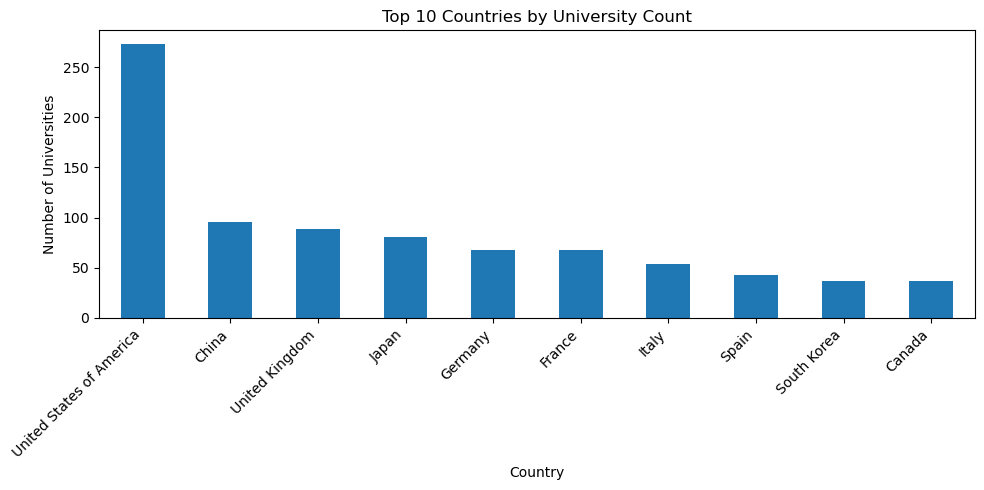

In [52]:
import matplotlib.pyplot as plt

top_10 = country_university_count.head(10)

top_10.plot(
    kind="bar",
    x="country_name",
    y="university_count",
    legend=False,
    figsize=(10, 5)
)

plt.title("Top 10 Countries by University Count")
plt.xlabel("Country")
plt.ylabel("Number of Universities")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Compare the three ranking systems -- Join the ranking tables

In [55]:
# Connect ranking records to criteria
ranking_analysis = university_ranking_year_clean.merge(
    ranking_criteria_clean,
    left_on="ranking_criteria_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

# Connect criteria to ranking systems
ranking_analysis = ranking_analysis.merge(
    ranking_system_clean,
    left_on="ranking_system_id",
    right_on="id",
    how="left",
    validate="many_to_one",
    suffixes=("", "_system")
)

print("Ranking analysis shape:", ranking_analysis.shape)

display(
    ranking_analysis[
        ["university_id", "year", "criteria_name", "system_name", "score"]
    ].head()
)


Ranking analysis shape: (29612, 9)


,university_id,year,criteria_name,system_name,score
0,1,2011,Teaching,Times Higher Education World University Ranking,100.0
1,5,2011,Teaching,Times Higher Education World University Ranking,98.0
2,2,2011,Teaching,Times Higher Education World University Ranking,98.0
3,3,2011,Teaching,Times Higher Education World University Ranking,98.0
4,6,2011,Teaching,Times Higher Education World University Ranking,91.0


### Count ranking records by system

In [58]:

ranking_system_summary = (
    ranking_analysis
    .groupby("system_name")
    .agg(
        total_records=("university_id", "size"),
        universities=("university_id", "nunique"),
        years=("year", "nunique"),
        missing_scores=("score", "count")
    )
    .reset_index()
)

# Rename count of non-missing scores for clarity
ranking_system_summary = ranking_system_summary.rename(
    columns={"missing_scores": "non_missing_scores"}
)

display(
    ranking_system_summary.sort_values(
        "total_records", ascending=False
    )
)


,system_name,total_records,universities,years,non_missing_scores
0,Center for World University Rankings,17600,1024,4,17600
2,Times Higher Education World University Ranking,6510,245,6,6380
1,Shanghai Ranking,5502,93,11,5502


### Analyse yearly trends

In [61]:

yearly_records = (
    ranking_analysis
    .groupby(["year", "system_name"])
    .agg(
        total_records=("university_id", "size"),
        available_scores=("score", "count"),
        average_score=("score", "mean")
    )
    .reset_index()
)

yearly_records["average_score"] = (
    yearly_records["average_score"].round(2)
)

display(yearly_records.head(15))


,year,system_name,total_records,available_scores,average_score
0,2005,Shanghai Ranking,497,497,35.89
1,2006,Shanghai Ranking,497,497,35.78
2,2007,Shanghai Ranking,511,511,35.41
3,2008,Shanghai Ranking,504,504,35.70
4,2009,Shanghai Ranking,497,497,35.53
5,2010,Shanghai Ranking,504,504,35.11
6,2011,Shanghai Ranking,497,497,35.31
7,2011,Times Higher Education World University Ranking,1110,1057,58.54
8,2012,Center for World University Rankings,800,800,60.21
9,2012,Shanghai Ranking,497,497,35.05


### What your current results show
- 1. Shanghai Ranking has records from 2005 onward in your displayed output.
- 2. Times Higher Education World University Ranking appears from 2011 onward in the displayed rows.
- 3. Center for World University Rankings appears from 2012 onward.
- 4. Some Times Higher Education records have missing scores, consistent with the missing values you found earlier.
- 5. The 2014 Center for World University Rankings result needs investigation before we interpret its average.

### Investigate the unusual 2014 record count

In [65]:
# Show record counts for each ranking system and year
display(
    ranking_analysis
    .groupby(["system_name", "year"])
    .agg(
        total_records=("university_id", "size"),
        unique_universities=("university_id", "nunique"),
        unique_criteria=("criteria_name", "nunique"),
        missing_scores=("score", lambda s: s.isna().sum())
    )
    .reset_index()
    .sort_values(["system_name", "year"])
)

,system_name,year,total_records,unique_universities,unique_criteria,missing_scores
0,Center for World University Rankings,2012,800,100,8,0
1,Center for World University Rankings,2013,800,100,8,0
2,Center for World University Rankings,2014,8000,1000,8,0
3,Center for World University Rankings,2015,8000,1000,8,0
4,Shanghai Ranking,2005,497,71,7,0
5,Shanghai Ranking,2006,497,71,7,0
6,Shanghai Ranking,2007,511,73,7,0
7,Shanghai Ranking,2008,504,72,7,0
8,Shanghai Ranking,2009,497,71,7,0
9,Shanghai Ranking,2010,504,72,7,0


### Check the ranking criteria for that system

In [68]:
# Inspect the Center for World University Rankings criteria
display(
    ranking_criteria_clean.merge(
        ranking_system_clean,
        left_on="ranking_system_id",
        right_on="id",
        how="left",
        suffixes=("_criteria", "_system")
    )[
        ["criteria_name", "system_name"]
    ].sort_values("system_name")
)

,criteria_name,system_name
20,Total CWUR,Center for World University Rankings
18,Citations Rank,Center for World University Rankings
17,Influence Rank,Center for World University Rankings
16,Publications Rank,Center for World University Rankings
15,Quality of Faculty Rank,Center for World University Rankings
14,Alumni Employment Rank,Center for World University Rankings
13,Quality of Education Rank,Center for World University Rankings
19,Patents Rank,Center for World University Rankings
12,Total Shanghai,Shanghai Ranking
11,PCP,Shanghai Ranking


### Check the 2014 records

In [71]:
cwur_2014 = ranking_analysis[
    (ranking_analysis["system_name"] ==
     "Center for World University Rankings") &
    (ranking_analysis["year"] == 2014)
]

print("Total records:", len(cwur_2014))
print("Unique universities:", cwur_2014["university_id"].nunique())
print("Unique criteria:", cwur_2014["criteria_name"].nunique())
print("Missing scores:", cwur_2014["score"].isna().sum())

display(cwur_2014.head(10))

Total records: 8000
Unique universities: 1000
Unique criteria: 8
Missing scores: 0


,university_id,ranking_criteria_id,year,score,id,ranking_system_id,criteria_name,id_system,system_name
12212,1,14,2014,1.0,14,3,Quality of Education Rank,3,Center for World University Rankings
12213,3,14,2014,11.0,14,3,Quality of Education Rank,3,Center for World University Rankings
12214,2,14,2014,3.0,14,3,Quality of Education Rank,3,Center for World University Rankings
12215,4,14,2014,2.0,14,3,Quality of Education Rank,3,Center for World University Rankings
12216,7,14,2014,7.0,14,3,Quality of Education Rank,3,Center for World University Rankings
12217,9,14,2014,13.0,14,3,Quality of Education Rank,3,Center for World University Rankings
12218,10,14,2014,4.0,14,3,Quality of Education Rank,3,Center for World University Rankings
12219,11,14,2014,10.0,14,3,Quality of Education Rank,3,Center for World University Rankings
12220,6,14,2014,5.0,14,3,Quality of Education Rank,3,Center for World University Rankings
12221,8,14,2014,9.0,14,3,Quality of Education Rank,3,Center for World University Rankings


### Analyse CWUR rankings for 2014

In [74]:
cwur_quality_2014 = ranking_analysis[
    (ranking_analysis["system_name"] ==
     "Center for World University Rankings") &
    (ranking_analysis["year"] == 2014) &
    (ranking_analysis["criteria_name"] ==
     "Quality of Education Rank")
]

# Add university names
cwur_quality_2014 = cwur_quality_2014.merge(
    university_clean[["id", "university_name"]],
    left_on="university_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

# Display the top 10
top_10_cwur_2014 = (
    cwur_quality_2014[
        ["university_name", "score"]
    ]
    .rename(columns={"score": "quality_of_education_rank"})
    .sort_values("quality_of_education_rank")
    .head(10)
    .reset_index(drop=True)
)

display(top_10_cwur_2014)

,university_name,quality_of_education_rank
0,Harvard University,1.0
1,University of Cambridge,2.0
2,Massachusetts Institute of Technology,3.0
3,"University of California, Berkeley",4.0
4,Princeton University,5.0
5,California Institute of Technology,6.0
6,University of Oxford,7.0
7,Ã‰cole normale supÃ©rieure - Paris,8.0
8,Yale University,9.0
9,University of Chicago,10.0


### Analyse university rankings over time

In [77]:
# Filter CWUR records for 2012–2016
cwur_trends = ranking_analysis[
    (ranking_analysis["system_name"] ==
     "Center for World University Rankings") &
    (ranking_analysis["year"].between(2012, 2016))
].copy()

# Summarise records and average rank by year and criterion
cwur_yearly_summary = (
    cwur_trends
    .groupby(["year", "criteria_name"])
    .agg(
        total_records=("university_id", "size"),
        average_rank=("score", "mean")
    )
    .reset_index()
)

cwur_yearly_summary["average_rank"] = (
    cwur_yearly_summary["average_rank"].round(2)
)

display(cwur_yearly_summary.head(20))

,year,criteria_name,total_records,average_rank
0,2012,Alumni Employment Rank,100,75.39
1,2012,Citations Rank,100,54.42
2,2012,Influence Rank,100,54.89
3,2012,Patents Rank,100,63.65
4,2012,Publications Rank,100,55.02
5,2012,Quality of Education Rank,100,66.42
6,2012,Quality of Faculty Rank,100,56.93
7,2012,Total CWUR,100,54.94
8,2013,Alumni Employment Rank,100,75.91
9,2013,Citations Rank,100,53.93


### Compare CWUR record counts across all years

In [80]:
cwur_year_check = (
    ranking_analysis[
        ranking_analysis["system_name"] ==
        "Center for World University Rankings"
    ]
    .groupby("year")
    .agg(
        total_records=("university_id", "size"),
        unique_universities=("university_id", "nunique"),
        unique_criteria=("criteria_name", "nunique"),
        missing_scores=("score", lambda s: s.isna().sum())
    )
    .reset_index()
)

display(cwur_year_check)

,year,total_records,unique_universities,unique_criteria,missing_scores
0,2012,800,100,8,0
1,2013,800,100,8,0
2,2014,8000,1000,8,0
3,2015,8000,1000,8,0


### Then analyse the overall CWUR rank

In [83]:
cwur_total_trend = (
    ranking_analysis[
        (ranking_analysis["system_name"] ==
         "Center for World University Rankings") &
        (ranking_analysis["criteria_name"] == "Total CWUR")
    ]
    .groupby("year")
    .agg(
        universities=("university_id", "nunique"),
        average_rank=("score", "mean"),
        median_rank=("score", "median"),
        best_rank=("score", "min"),
        worst_rank=("score", "max")
    )
    .round(2)
    .reset_index()
)

display(cwur_total_trend)

,year,universities,average_rank,median_rank,best_rank,worst_rank
0,2012,100,54.94,50.0,43.0,100.0
1,2013,100,55.29,50.0,44.0,100.0
2,2014,1000,47.27,45.0,44.0,100.0
3,2015,1000,46.80,45.0,44.0,100.0


### Create a trend chart

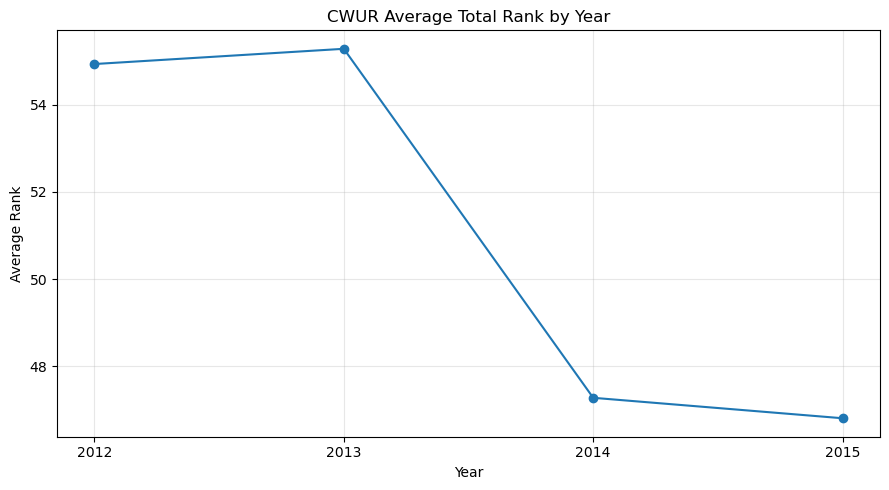

In [86]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    cwur_total_trend["year"],
    cwur_total_trend["average_rank"],
    marker="o"
)

plt.title("CWUR Average Total Rank by Year")
plt.xlabel("Year")
plt.ylabel("Average Rank")
plt.xticks(cwur_total_trend["year"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Compare countries by average university rank

In [89]:

# Filter CWUR Total Rank for 2015
cwur_2015 = ranking_analysis[
    (ranking_analysis["system_name"] ==
     "Center for World University Rankings") &
    (ranking_analysis["criteria_name"] == "Total CWUR") &
    (ranking_analysis["year"] == 2015)
].copy()

# Add university and country names
cwur_2015 = cwur_2015.merge(
    university_clean[["id", "university_name", "country_id"]],
    left_on="university_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

cwur_2015 = cwur_2015.merge(
    country_clean[["id", "country_name"]],
    left_on="country_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

# Summarise country performance
country_rank_summary = (
    cwur_2015
    .groupby("country_name")
    .agg(
        universities=("university_id", "nunique"),
        average_rank=("score", "mean"),
        median_rank=("score", "median")
    )
    .reset_index()
)

country_rank_summary = country_rank_summary[
    country_rank_summary["universities"] >= 5
].sort_values("average_rank")

display(country_rank_summary.head(10).round(2))


,country_name,universities,average_rank,median_rank
24,Iran,8,44.00,44.0
53,Turkey,10,44.10,44.0
21,Hungary,6,44.17,44.0
36,Poland,9,44.22,44.0
12,Czech Republic,5,44.40,44.0
23,India,16,44.50,44.0
4,Brazil,18,44.61,44.0
19,Greece,7,44.71,45.0
48,Spain,40,44.72,44.0
8,China,83,44.80,44.0


### Analyse student statistics with Pandas

In [92]:

# Add university and country details to yearly statistics
student_analysis = university_year_clean.merge(
    university_clean[["id", "university_name", "country_id"]],
    left_on="university_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

student_analysis = student_analysis.merge(
    country_clean[["id", "country_name"]],
    left_on="country_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

print("Dataset shape:", student_analysis.shape)
display(student_analysis.head())


Dataset shape: (1085, 11)


,university_id,year,num_students,student_staff_ratio,pct_international_students,pct_female_students,id_x,university_name,country_id,id_y,country_name
0,1,2011,20152,8.9,25,NaN,1,Harvard University,73,73,United States of America
1,5,2011,2243,6.9,27,33.0,5,California Institute of Technology,73,73,United States of America
2,2,2011,11074,9.0,33,37.0,2,Massachusetts Institute of Technology,73,73,United States of America
3,3,2011,15596,7.8,22,42.0,3,Stanford University,73,73,United States of America
4,6,2011,7929,8.4,27,45.0,6,Princeton University,73,73,United States of America


### Calculate yearly trends

In [95]:

yearly_student_summary = (
    student_analysis
    .groupby("year")
    .agg(
        universities=("university_id", "nunique"),
        total_students=("num_students", "sum"),
        avg_student_staff_ratio=("student_staff_ratio", "mean"),
        avg_international_students=(
            "pct_international_students", "mean"
        ),
        avg_female_students=("pct_female_students", "mean")
    )
    .round(2)
    .reset_index()
)

display(yearly_student_summary)


,year,universities,total_students,avg_student_staff_ratio,avg_international_students,avg_female_students
0,2011,185,4463626,15.67,19.31,48.98
1,2012,196,4683788,15.39,19.68,49.85
2,2013,197,4738181,15.54,19.74,49.33
3,2014,198,4660093,15.56,19.93,49.23
4,2015,199,4751004,15.93,19.42,49.14
5,2016,110,2754163,16.50,20.69,50.27


### Verify your yearly summary

In [98]:

print(yearly_student_summary.columns.tolist())
display(yearly_student_summary.head())

['year', 'universities', 'total_students', 'avg_student_staff_ratio', 'avg_international_students', 'avg_female_students']


,year,universities,total_students,avg_student_staff_ratio,avg_international_students,avg_female_students
0,2011,185,4463626,15.67,19.31,48.98
1,2012,196,4683788,15.39,19.68,49.85
2,2013,197,4738181,15.54,19.74,49.33
3,2014,198,4660093,15.56,19.93,49.23
4,2015,199,4751004,15.93,19.42,49.14


### Create a student trend chart

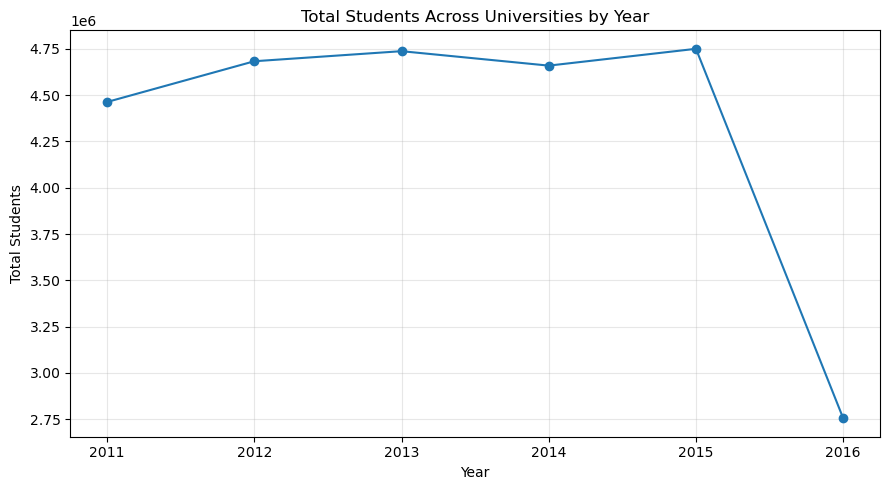

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    yearly_student_summary["year"],
    yearly_student_summary["total_students"],
    marker="o"
)

plt.title("Total Students Across Universities by Year")
plt.xlabel("Year")
plt.ylabel("Total Students")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Analyse international students by country

In [104]:

# Filter the 2016 university records
student_2016 = student_analysis[
    student_analysis["year"] == 2016
].copy()

# Summarise student statistics by country
country_student_summary = (
    student_2016
    .groupby("country_name")
    .agg(
        universities=("university_id", "nunique"),
        avg_international_students=(
            "pct_international_students", "mean"
        ),
        avg_female_students=("pct_female_students", "mean"),
        avg_student_staff_ratio=("student_staff_ratio", "mean")
    )
    .reset_index()
)

# Include countries with at least 3 universities
country_student_summary = (
    country_student_summary[
        country_student_summary["universities"] >= 3
    ]
    .sort_values("avg_international_students", ascending=False)
    .head(10)
    .round(2)
)

display(country_student_summary)


,country_name,universities,avg_international_students,avg_female_students,avg_student_staff_ratio
19,United Kingdom,20,34.25,52.40,14.48
0,Australia,4,33.25,53.25,26.02
3,Canada,5,20.00,52.50,19.32
5,France,3,18.00,54.50,12.57
20,United States of America,36,17.53,48.00,10.56
17,Sweden,4,15.75,54.75,17.00
6,Germany,11,14.82,54.30,32.15
12,Netherlands,6,10.67,54.50,17.95
15,South Korea,4,8.00,26.33,13.58


### Top countries by international-student percentage

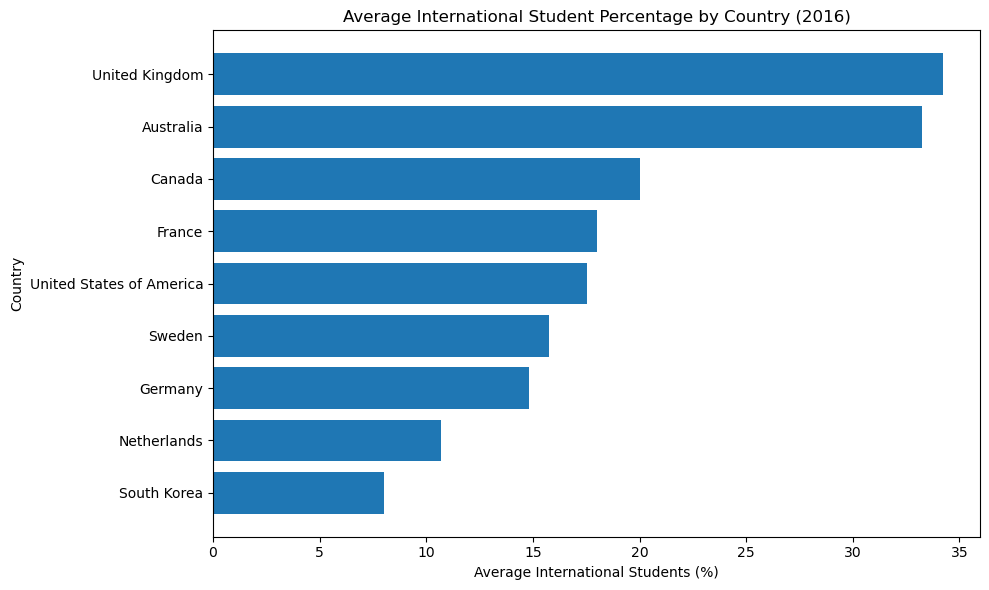

In [107]:

import matplotlib.pyplot as plt

plot_data = country_student_summary.sort_values(
    "avg_international_students",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["country_name"],
    plot_data["avg_international_students"]
)
plt.title("Average International Student Percentage by Country (2016)")
plt.xlabel("Average International Students (%)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


### Export your analysis for Excel

In [110]:

output_folder = project_folder / "python_outputs"
output_folder.mkdir(exist_ok=True)

yearly_student_summary.to_csv(
    output_folder / "yearly_student_summary.csv",
    index=False
)

country_university_count.to_csv(
    output_folder / "country_university_count.csv",
    index=False
)

country_student_summary.to_csv(
    output_folder / "country_student_summary_2016.csv",
    index=False
)

cwur_total_trend.to_csv(
    output_folder / "cwur_total_rank_trend.csv",
    index=False
)

print("Summary files saved to:", output_folder)


Summary files saved to: C:\Users\singh\OneDrive\Desktop\Resume Projects\Global Universities Sucess Analysis\python_outputs


In [112]:
output_folder = project_folder / "python_outputs"

for file in sorted(output_folder.glob("*.csv")):
    print(file.name)

country_student_summary_2016.csv
country_university_count.csv
cwur_total_rank_trend.csv
yearly_student_summary.csv


In [116]:
import pandas as pd
from pathlib import Path

project_folder = Path(
    r"C:\Users\singh\OneDrive\Desktop\Resume Projects\Global Universities Sucess Analysis"
)

output_folder = project_folder / "python_outputs"

country_student_summary_2016 = pd.read_csv(
    output_folder / "country_student_summary_2016.csv"
)

print(country_student_summary_2016.head())

               country_name  universities  avg_international_students  \
0            United Kingdom            20                       34.25   
1                 Australia             4                       33.25   
2                    Canada             5                       20.00   
3                    France             3                       18.00   
4  United States of America            36                       17.53   

   avg_female_students  avg_student_staff_ratio  
0                52.40                    14.48  
1                53.25                    26.02  
2                52.50                    19.32  
3                54.50                    12.57  
4                48.00                    10.56  


In [118]:
country_student_summary_2016[
    ["country_name", "universities", "avg_international_students"]
].sort_values(
    "avg_international_students",
    ascending=False
).head(10)

,country_name,universities,avg_international_students
0,United Kingdom,20,34.25
1,Australia,4,33.25
2,Canada,5,20.00
3,France,3,18.00
4,United States of America,36,17.53
5,Sweden,4,15.75
6,Germany,11,14.82
7,Netherlands,6,10.67
8,South Korea,4,8.00


### KPI
1. The United Kingdom had the highest average international-student percentage among the countries shown, at 34.25%.
2. Australia followed at 33.25%, based on four universities in the dataset.
3. The United States had 36 universities in the dataset, with an average international-student percentage of 17.53%.
4. Country averages are based on the universities represented in the 2016 data; they should not be interpreted as national statistics for all universities.